# 1. Two kinds of days

**Notions:**

- how a real situation is turned into a payoff matrix, step by step;
- why the same two renters do **not** play the same game on a quiet day and on a busy day;
- how to recognise the type of a 2×2 game from its best responses.


In [ ]:
#import of axelrod can take 18 sec. !
import axelrod as axl
import numpy as np
import matplotlib.pyplot as plt
from bikes import *

## 1.1 The situation

Two bike renters, *you* and *your neighbour*, have shops in the same street.

| Assumption | Variable | Value |
|---|---|---|
| bikes per shop | FLEET | 20 |
| usual price | USUAL | 15 (EUR per day) |
| low price | LOW | 10 (EUR per day) when the move D is to undercut|
| high price | HIGH | 25 (EUR per day) when the move D is to surge|
| customers in the street | QUIET_CUSTOMERS,<br>  BUSY_CUSTOMERS | 20 (on a **quiet** day),<br> 60 (on a **busy** day) |
| type of days in a city week | CITY_WEEK | busy,busy,busy,busy,busy,quiet,quiet |
| type of days in a tourist week | TOURIST_WEEK | quiet,quiet,quiet,quiet,quiet,busy,busy |
| game matrix on quiet day | QUIET_DAY | 2x2 game matrix with revenues by move (C,D) |
| game matrix on busy day | BUSY_DAY | 2x2 game matrix with revenues by move (C,D),<br> taking into account resentment about surge|

- Customers go to the cheaper shop first; when it has no bike left, they go next door
- At 25 EUR, only 60 % of customers still want a bike (the others walk or take the bus)
- bad review: a customer who paid 25 EUR while the shop next door charged 15 EUR feels cheated: we count 12.5 EUR of lost future business per customer.
- market price: if *both* shops charge 25 EUR, the feeling is weaker, renters get a loss of 5 EUR per customer

Every morning, each renter makes one decision:
- **C**: keep the usual price (15 EUR);
- **D**: *play the day*, that is: undercut to 10 EUR on a quiet day, or surge to 25 EUR on a busy day.

The file `bikes.py` contains these variables and a lot of functions, classes...  
For example, `revenue(my_price, other_price, customers)` turns the prices into revenues according the estimated choice of the customers.

In [2]:
#USUAL=15, HIGH=25, LOW=10
print(f"quiet day, both at {USUAL} EUR    (C,C)    :", revenue(USUAL, USUAL, 20), "EUR each")
print(f"quiet day, I undercut to {LOW} EUR (D,C) :", revenue(LOW, USUAL, 20), "EUR for me,", revenue(USUAL, LOW, 20), "for my neighbour")

quiet day, both at 15 EUR    (C,C)    : 150.0 EUR each
quiet day, I undercut to 10 EUR (D,C) : 200 EUR for me, 0 for my neighbour


With 20 customers and the same price, each shop rents 10 bikes: $10 \times 15 = 150$ EUR.  
If I undercut, all 20 customers come to me: $20 \times 10 = 200$ EUR, and my neighbour rents nothing.

---

**Exercise 1** *(≈ 4 lines)*.  
 - Use `revenue` to compute the two missing cells of the quiet day: 
  - my revenue when **both** shops undercut to 10 EUR (D,D), 
  - and my revenue when I keep 15 EUR while my neighbour undercuts (C,D). 
 - Then compare your four numbers with the matrix printed by the call to `show_game(QUIET_DAY, ("15 EUR", "10 EUR"))`. 

both undercut (D,D), I get           : 100.0
I keep 15, he undercuts (C,D), I get : 0
---
Quiet day (20 customers)
              15 EUR        10 EUR       <- neighbour
  15 EUR    (150, 150)     (0, 200)   
  10 EUR     (200, 0)     (100, 100)  



---
## 1.2 The quiet day: a price war

Read the matrix line by line, you can say:

- "if my neighbour keeps 15 EUR, I earn 150 by keeping my price and 200 by undercutting;"
- "if my neighbour undercuts, I earn 0 by keeping my price and 100 by undercutting."

Whatever my neighbour does, undercutting pays more.   
"Yet if we both undercut, we earn 100 each instead of 150!"  
This is a **prisoner's dilemma**: $T=200 > R=150 > P=100 > S=0$.

`describe` lists my best answers and the Nash equilibria of a day (computed with `nashpy`, pure and mixed).

In [5]:
print("quiet day :", QUIET_DAY)
describe(QUIET_DAY)

quiet day : Axelrod game: (R,P,S,T) = (150.0, 100.0, 0.0, 200.0)
  if the neighbour plays C, my best answer is D
  if the neighbour plays D, my best answer is D
  Nash equilibria (me, neighbour) -> revenues:
    (D, D) -> (100, 100)


---
## 1.3 The busy day, without reputation

On a busy day, 60 customers arrive for 40 bikes. Let us first ignore bad reviews (`bad_review=0, grumble=0`).

In [6]:
#USUAL=15, HIGH=25, LOW=10
busy_no_reviews = day_game(60, HIGH, bad_review=0, grumble=0)

show_game(busy_no_reviews, moved_price=HIGH, title="Busy day, no reputation cost")
describe(busy_no_reviews)

Busy day, no reputation cost
              15 EUR        25 EUR       <- neighbour
  15 EUR    (300, 300)    (300, 500)  
  25 EUR    (500, 300)    (450, 450)  

  if the neighbour plays C, my best answer is D
  if the neighbour plays D, my best answer is D
  Nash equilibria (me, neighbour) -> revenues:
    (D, D) -> (450, 450)


> **Reading.** 
> - Surging to 25 EUR is always better, and when both shops surge they both earn more (450 instead of 300). 
> - There is **no dilemma between the renters** here: their interests are aligned. The only one who loses is the customer, who pays more or gives up.

This is what the intuition says: "on a busy day, everything will be rented anyway, so why not raise the price?"

## 1.4 The busy day, with reputation

Now let us count the bad reviews.  
The default values of `bikes.py` is a penalty of 12.5 € if I surge and not my neighbor, and a penalty of 5€ for both of us if we surge.


In [22]:
# BUSY_DAY is the matrix game for a busy day with reputation cost 
show_game(BUSY_DAY, moved_price=HIGH, title="Busy day (60 customers), with reputation")
describe(BUSY_DAY)

Busy day (60 customers), with reputation
              15 EUR        25 EUR       <- neighbour
  15 EUR    (300, 300)    (300, 250)  
  25 EUR    (250, 300)    (360, 360)  

  if the neighbour plays C, my best answer is C
  if the neighbour plays D, my best answer is D
  Nash equilibria (me, neighbour) -> revenues:
    (C, C) -> (300, 300)
    (D, D) -> (360, 360)
    (C 55% / D 45%, C 55% / D 45%) -> (300, 300)


> **Reading.** The game has changed again:
> 
> - if my neighbour keeps 15 EUR, surging alone is a bad idea (250 < 300): my customers compare, feel cheated, and I lose future business;
> - if my neighbour surges, I should surge too (360 > 300).

There are two pure equilibria: both at 15 EUR, or both at 25 EUR.   
`describe` also finds a third, **mixed** equilibrium: if my neighbour keeps 15 EUR with probability 6/11 (≈ 55 %), I earn 300 EUR whatever I choose ($300 = 250 \times \frac{6}{11} + 360 \times \frac{5}{11}$).  

It is the tipping point between the two pure equilibria.  

This is a **coordination game** (of the stag hunt family): the difficulty is not to resist a temptation, but to **move together**.  

Note that the "good" outcome for the renters (both at 25 EUR) is the bad one for the customers.  
**If the two renters *agreed* on it explicitly, *it would be an illegal price agreement* (a cartel)**; if each one just follows the other, it is called *tacit coordination*.

---

**Exercise 2** *(≈ 8 lines, with a plot)*.  
How busy must the day be for this coordination to appear?  
- For each number of customers from 20 to 60, build a day game with D is a surge (`g=day_game(customers, HIGH)`) and record its four values $R, P, S, T$ (given by `g.RPST()`). 
- Plot the four curves against the number of customers. 
- From how many customers is surging together ($P$) better than keeping the usual price ($R$)?

In [ ]:
# Exercise 2: your code here


In [8]:
g = day_game(20, HIGH)
g.RPST()

(150.0, 120.0, 300.0, 0.0)

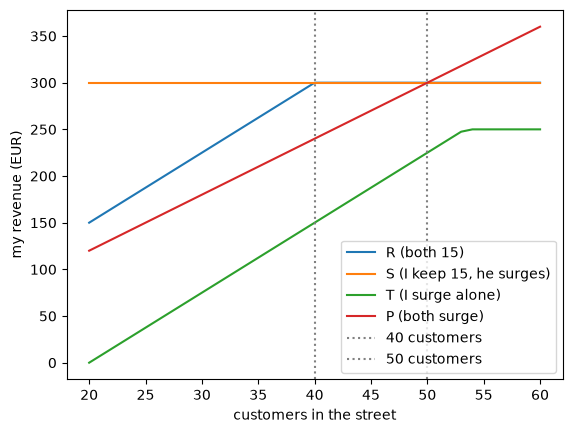

> **Reading.**   
> Up to 50 customers, surging together does not beat the usual price ($P \le R$): too many customers give up at 25 EUR.  
> Above 50 customers, $P > R$ and the coordination game appears.  
> Surging **alone** ($T$) never beats the usual price in this model: the bad reviews cost too much.

So the "type of game" is not a property of the two renters: it depends on the **demand of the day**.

## Key points

| Day | Game | What matters |
|---|---|---|
| quiet (20 customers) | prisoner's dilemma | resisting the temptation to undercut, and making undercutting not pay |
| busy, no reputation | no dilemma | nothing: both surge, the customer pays |
| busy, with reputation | coordination | surging only if the other one does |

In the next chapter, the two renters meet **every day of a season**, and the type of day changes from one day to the next.